# Target Distribution


TARGET
Good    282686
Bad      24825
Name: count, dtype: int64
TARGET
Good    91.927118
Bad      8.072882
Name: count, dtype: float64


C:\Users\USER\AppData\Local\Temp\ipykernel_15264\52096382.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='TARGET',data=df_target, palette='tab10')


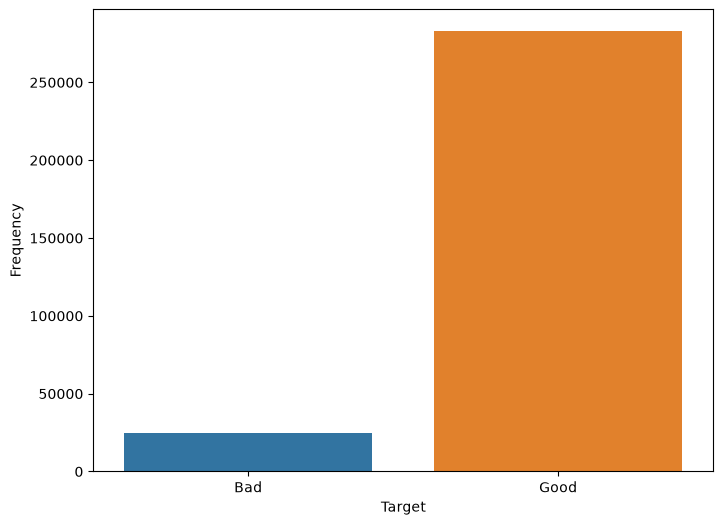

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
df = pd.read_csv("../data/application_train.csv")
df_target = df[['TARGET']]
df_target['TARGET'] = np.where(df_target['TARGET']==1,'Bad','Good') # change from numeric value to explainabe language
print(df_target['TARGET'].value_counts()) # numeric
print(df_target['TARGET'].value_counts()/len(df_target)*100) # percentage

fig = plt.figure(figsize=(8,6))
sns.countplot(x='TARGET',data=df_target, palette='tab10')
plt.xlabel('Target')
plt.ylabel('Frequency')
plt.grid(False)
plt.show();

In [4]:
count_good = len(df_target.loc[df_target['TARGET']=='Good'])
count_bad = len(df_target.loc[df_target['TARGET']=='Bad'])

print("Imbalance Ratio (IR) = 1:{}".format(int(count_good/count_bad)))


Imbalance Ratio (IR) = 1:11


In [5]:
df.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [7]:
uni = pd.DataFrame({
    "dtype": df.dtypes,
    "missing_%": (df.isnull().mean() * 100).round(1),
    "n_unique": df.nunique(),
})
uni["corr_with_target"] = df.select_dtypes("number").corrwith(df["TARGET"]).round(3)
uni.sort_values("corr_with_target", key=abs, ascending=False)

,dtype,missing_%,n_unique,corr_with_target
TARGET,int64,0.0,2,1.000
EXT_SOURCE_3,float64,19.8,814,-0.179
EXT_SOURCE_2,float64,0.2,119831,-0.160
EXT_SOURCE_1,float64,56.4,114584,-0.155
DAYS_BIRTH,int64,0.0,17460,0.078
...,...,...,...,...
ORGANIZATION_TYPE,str,0.0,58,NaN
FONDKAPREMONT_MODE,str,68.4,4,NaN
HOUSETYPE_MODE,str,50.2,3,NaN
WALLSMATERIAL_MODE,str,50.8,7,NaN
